In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy.stats import poisson


In [3]:
rng = np.random.default_rng(42)
n = 500

df = pd.DataFrame({
    "demand": rng.integers(50, 151, n),
    "supply": rng.integers(45, 141, n),
    "distance_km": rng.uniform(1, 15, n).round(1),
    "peak": rng.choice(
        ["Yes", "No"], n, p=[0.45, 0.55]
    ),
    "weather": rng.choice(
        ["Clear", "Rain"], n, p=[0.75, 0.25]
    )
})

noise = rng.normal(0, 1.7, n)

df["wait_min"] = (
    8
    + 0.12 * (df["demand"] - 100)
    - 0.09 * (df["supply"] - 90)
    + 0.25 * (df["distance_km"] - 7)
    + 1.5 * (df["peak"] == "Yes")
    + 2.0 * (df["weather"] == "Rain")
    + noise
).clip(lower=0.5).round(2)

# Binary target for Logistic Regression
df["late"] = (df["wait_min"] >= 10).astype(int)

display(df.head())
print(df.shape)
print(df["late"].value_counts())

,demand,supply,distance_km,peak,weather,wait_min,late
0,59,55,11.3,Yes,Clear,7.06,0
1,128,107,13.4,No,Rain,14.97,1
2,116,137,13.9,Yes,Clear,6.87,0
3,94,128,8.1,Yes,Clear,5.15,0
4,93,71,8.3,No,Rain,10.20,1


(500, 7)
late
0    290
1    210
Name: count, dtype: int64


           demand    wait_min
count  500.000000  500.000000
mean    99.938000    9.252580
std     28.876597    4.805493
min     50.000000    0.500000
25%     76.000000    5.655000
50%     99.500000    9.230000
75%    125.250000   12.870000
max    150.000000   21.610000
Correlation: 0.7235822950357308


<Figure size 800x500 with 0 Axes>

Text(0.5, 0, 'Demand')

Text(0, 0.5, 'Waiting Time (minutes)')

Text(0.5, 1.0, 'Demand vs. Passenger Waiting Time')

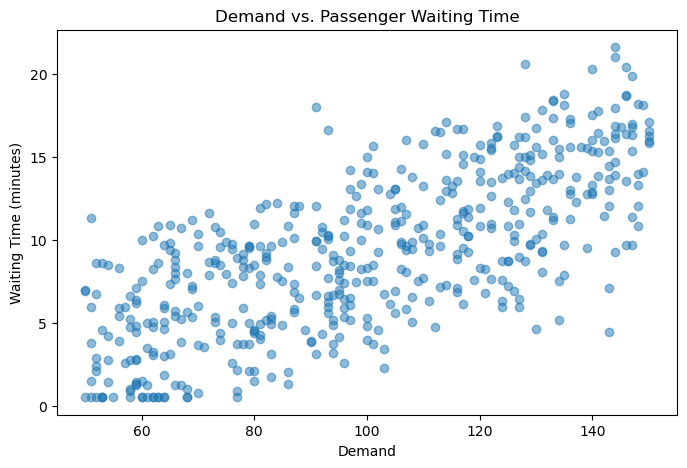

In [4]:
# Task 1. Examine the relationship between passenger demand and waiting time.

print(df[["demand", "wait_min"]].describe())

correlation = df["demand"].corr(df["wait_min"])
print("Correlation:", correlation)

plt.figure(figsize=(8, 5))

plt.scatter(
    df["demand"],
    df["wait_min"],
    alpha=0.5
)

plt.xlabel("Demand")
plt.ylabel("Waiting Time (minutes)")
plt.title("Demand vs. Passenger Waiting Time")
plt.show()

In [5]:
# Task 2. Fit a simple linear regression with demand as the predictor.

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[["demand"]]
y = df["wait_min"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])

LinearRegression()

Intercept: -2.8483691599031395
Slope: 0.12099824382503019


<Figure size 800x500 with 0 Axes>

Text(0.5, 0, 'Demand')

Text(0, 0.5, 'Waiting Time (minutes)')

Text(0.5, 1.0, 'Simple Linear Regression')

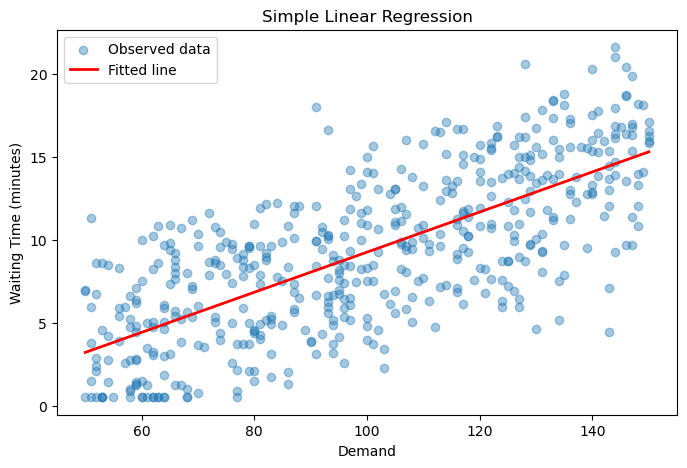

In [6]:
# Task 3. Visualize the fitted regression line.

x_line = np.linspace(
    df["demand"].min(),
    df["demand"].max(),
    100
)

x_line_df = pd.DataFrame({
    "demand": x_line
})

y_line = model.predict(x_line_df)

plt.figure(figsize=(8, 5))

plt.scatter(
    df["demand"],
    df["wait_min"],
    alpha=0.4,
    label="Observed data"
)

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Fitted line"
)

plt.xlabel("Demand")
plt.ylabel("Waiting Time (minutes)")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [7]:
# Task 4. Predict waiting time for a new demand level.

new_data = pd.DataFrame({
    "demand": [120]
})

prediction = model.predict(new_data)

print("Predicted wait:", prediction[0])

Predicted wait: 11.671420099100484


<Figure size 800x500 with 0 Axes>

Text(0.5, 0, 'Predicted Waiting Time')

Text(0, 0.5, 'Residual')

Text(0.5, 1.0, 'Residual Plot')

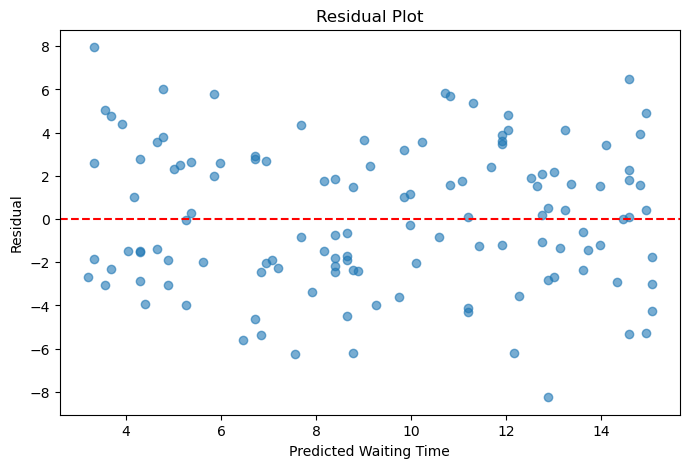

In [8]:
# Task 5. Calculate residuals and draw a residual plot.

y_pred = model.predict(X_test)

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Waiting Time")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()

In [9]:
# Task 6. Calculate MAE, RMSE, and R².

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 2.792424966503308
RMSE: 3.284794210001082
R²: 0.5463479494356478


In [10]:
# Task 7. Compare the regression with a mean-only baseline.

baseline_pred = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test, baseline_pred
)

print("Baseline MAE:", baseline_mae)
print("Regression MAE:", mae)

Baseline MAE: 4.083957973333333
Regression MAE: 2.792424966503308


In [11]:
# Task 8. Add supply, distance, peak period, and weather as predictors.

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

features = [
    "demand", "supply",
    "distance_km", "peak", "weather"
]

numeric_features = [
    "demand", "supply", "distance_km"
]

categorical_features = ["peak", "weather"]

X = df[features]
y = df["wait_min"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

preprocess = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), categorical_features)
])

multi_model = Pipeline([
    ("prep", preprocess),
    ("reg", LinearRegression())
])

multi_model.fit(X_train, y_train)

y_pred_multi = multi_model.predict(X_test)

print(
    "Multiple Regression MAE:",
    mean_absolute_error(y_test, y_pred_multi)
)

print(
    "Multiple Regression R²:",
    r2_score(y_test, y_pred_multi)
)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['demand', 'supply',
                                                   'distance_km']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['peak', 'weather'])])),
                ('reg', LinearRegression())])

Multiple Regression MAE: 1.5189762273027343
Multiple Regression R²: 0.8400206478553025
